# Analisis Time Series Pasar Saham & Keuangan (2020–2026)
**Midterm Project — Visualisasi Data (CAK4XBB3)**
**Kelompok Cihuy**

| No | Nama | NIM | Bagian |
|----|------|-----|--------|
| 1 | Adhyatma Chrysostomos Davu | 103012340479 | Data & kerangka notebook |
| 2 | Raffa Anung El Haqqi | 103012300163 | Line Plot & Area Plot |
| 3 | Tristan Satria Perdana Hermawan | 103012300253 | Multiple Time Series & Seasonal/Heatmap |
| 4 | Naufal Rafif Hidayat | 103012300403 | Analisis Tren |
| 5 | Ahmad Naufal Ramadhan | 103012300239 | Kesimpulan, Deklarasi AI, Daftar Pustaka |

**Sumber data:** Yahoo Finance — https://finance.yahoo.com (diunduh dengan library `yfinance`)

## 1. Pendahuluan
*(Davu)*

Pasar keuangan Indonesia dan global mengalami beberapa guncangan besar sejak 2020: crash pandemi COVID-19 (Maret 2020), lonjakan inflasi dan kenaikan suku bunga global (2022), serta reli aset kripto dan emas pada 2024–2025. Data harga harian adalah contoh time series nyata yang mengandung **tren**, **pola musiman/periodik**, **siklus**, dan **noise**, sehingga cocok untuk dianalisis dengan teknik visualisasi time series.

**Tujuan analisis:**
1. Melihat pola pergerakan utama IHSG dan aset keuangan lain selama 2020–2026.
2. Membandingkan kinerja beberapa kelas aset (indeks saham, saham bank, kripto, emas, kurs) dalam satu grafik.
3. Mencari pola musiman/periodik pada imbal hasil (return) harian.
4. Mengidentifikasi tren jangka pendek dan panjang dengan Moving Average dan fitting model.

## 2. Dataset
*(Davu)*

### 2.1 Sumber data
Data diambil dari **Yahoo Finance** (https://finance.yahoo.com) menggunakan library Python `yfinance`. Data berupa harga harian (Open, High, Low, Close, Volume) periode **1 Januari 2020 – 31 Oktober 2026** untuk 9 aset dari 5 kategori:

| Kategori | Ticker Yahoo | Nama di notebook | Mata uang |
|----------|--------------|------------------|-----------|
| Indeks | `^JKSE` | IHSG | IDR (poin) |
| Indeks | `^GSPC` | S&P 500 | USD (poin) |
| Saham Bank | `BBCA.JK` | BBCA | IDR |
| Saham Bank | `BBRI.JK` | BBRI | IDR |
| Saham Bank | `BMRI.JK` | BMRI | IDR |
| Saham Bank | `BBNI.JK` | BBNI | IDR |
| Kripto | `BTC-USD` | Bitcoin | USD |
| Komoditas | `GC=F` | Emas (futures) | USD/troy ounce |
| Kurs | `IDR=X` | USD/IDR | IDR per 1 USD |

Harga sudah **disesuaikan (adjusted)** terhadap stock split dan dividen (`auto_adjust=True`).

Script unduhan: [`data/download_data.py`](data/download_data.py). Notebook ini membaca file CSV hasil unduhan agar hasil analisis **reproducible** (tidak berubah setiap kali dijalankan). Set `DOWNLOAD_ULANG = True` untuk mengunduh ulang dari Yahoo Finance.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

pd.set_option("display.float_format", "{:,.2f}".format)

# Gaya grafik bersama untuk SEMUA anggota (biar konsisten)
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

# Palet Okabe-Ito (ramah buta warna, Minggu 1) -> satu warna tetap per aset
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2",
             "#D55E00", "#CC79A7", "#000000", "#999999"]
ASET = ["IHSG", "S&P 500", "BBCA", "BBRI", "BMRI", "BBNI", "Bitcoin", "Emas", "USD/IDR"]
WARNA = dict(zip(ASET, ["#0072B2", "#D55E00", "#009E73", "#56B4E9", "#E69F00",
                        "#CC79A7", "#F0E442", "#999999", "#000000"]))
KATEGORI = {"IHSG": "Indeks", "S&P 500": "Indeks", "BBCA": "Saham Bank", "BBRI": "Saham Bank",
            "BMRI": "Saham Bank", "BBNI": "Saham Bank", "Bitcoin": "Kripto",
            "Emas": "Komoditas", "USD/IDR": "Kurs"}

# Simpan grafik ke folder figures/ untuk laporan & slide
from pathlib import Path
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
def simpan(nama):
    plt.savefig(FIG_DIR / f"{nama}.png", dpi=150, bbox_inches="tight")

### 2.2 Load data mentah

In [2]:
DOWNLOAD_ULANG = False   # True = unduh ulang dari Yahoo Finance (butuh internet)

if DOWNLOAD_ULANG:
    import subprocess, sys
    subprocess.run([sys.executable, "data/download_data.py"], check=True)

raw = pd.read_csv("data/raw_yahoo_finance.csv", parse_dates=["Date"])
print("Ukuran data mentah:", raw.shape)
raw.head()

Ukuran data mentah: (15936, 9)


,Date,Ticker,Nama,Kategori,Open,High,Low,Close,Volume
0,2020-01-01,BTC-USD,Bitcoin,Kripto,"7,194.89","7,254.33","7,174.94","7,200.17","18,565,664,997.00"
1,2020-01-01,IDR=X,USD/IDR,Kurs,"13,862.00","13,876.00","13,681.83","13,690.37",0.00
2,2020-01-02,BBCA.JK,BBCA,Saham Bank,"5,505.30","5,575.20","5,492.97","5,501.19","49,445,000.00"
3,2020-01-02,BBNI.JK,BBNI,Saham Bank,"2,878.24","2,878.24","2,841.69","2,841.69","18,602,600.00"
4,2020-01-02,BBRI.JK,BBRI,Saham Bank,"2,674.09","2,680.16","2,649.78","2,680.16","45,886,302.00"


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15936 entries, 0 to 15935
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      15936 non-null  datetime64[us]
 1   Ticker    15936 non-null  str           
 2   Nama      15936 non-null  str           
 3   Kategori  15936 non-null  str           
 4   Open      15936 non-null  float64       
 5   High      15936 non-null  float64       
 6   Low       15936 non-null  float64       
 7   Close     15936 non-null  float64       
 8   Volume    15936 non-null  float64       
dtypes: datetime64[us](1), float64(5), str(3)
memory usage: 1.1 MB


In [4]:
# Rentang waktu & jumlah observasi per aset
ringkas = (raw.groupby(["Kategori", "Nama"])
              .agg(mulai=("Date", "min"), akhir=("Date", "max"), jumlah_hari=("Date", "count"))
              .sort_values("Kategori"))
ringkas

mulai      akhir  jumlah_hari
Kategori   Nama                                      
Indeks     IHSG    2020-01-02 2026-10-30         1645
           S&P 500 2020-01-02 2026-10-30         1717
Komoditas  Emas    2020-01-02 2026-10-30         1720
Kripto     Bitcoin 2020-01-01 2026-10-31         2496
Kurs       USD/IDR 2020-01-01 2026-10-30         1778
Saham Bank BBCA    2020-01-02 2026-10-30         1645
           BBNI    2020-01-02 2026-10-30         1645
           BBRI    2020-01-02 2026-10-30         1645
           BMRI    2020-01-02 2026-10-30         1645

**Catatan:** jumlah hari berbeda karena kalender perdagangan berbeda:
- **Bitcoin** diperdagangkan 7 hari seminggu (termasuk Sabtu–Minggu).
- **Bursa Efek Indonesia** (IHSG & saham bank) libur di hari libur nasional Indonesia (Lebaran, Natal, dll.).
- **S&P 500 & Emas** libur mengikuti kalender Amerika Serikat.
- **Kurs USD/IDR** tersedia setiap hari kerja.

### 2.3 Cek missing values & data cleaning

In [5]:
# Ubah ke format wide: kolom = aset, index = tanggal (kolom waktu jadi index)
close_raw = raw.pivot(index="Date", columns="Nama", values="Close")[ASET]
volume_raw = raw.pivot(index="Date", columns="Nama", values="Volume")[ASET]

missing = pd.DataFrame({
    "missing": close_raw.isna().sum(),
    "persen (%)": close_raw.isna().mean() * 100,
})
missing

,missing,persen (%)
Nama,,
IHSG,851,34.09
S&P 500,779,31.21
BBCA,851,34.09
BBRI,851,34.09
BMRI,851,34.09
BBNI,851,34.09
Bitcoin,0,0.00
Emas,776,31.09
USD/IDR,718,28.77


Langkah cleaning:
1. **Samakan kalender ke hari kerja (Senin–Jumat)** — data Bitcoin di akhir pekan dibuang agar semua aset bisa dibandingkan pada tanggal yang sama.
2. **Isi hari libur bursa dengan harga terakhir (forward fill, maks. 5 hari)** — saat bursa libur, harga tidak berubah, jadi harga penutupan terakhir adalah nilai yang benar, bukan data karangan.
3. **Volume tidak di-forward fill** — hari libur artinya tidak ada transaksi, jadi diisi 0.
4. Kurs `USD/IDR` tidak punya data volume di Yahoo Finance (selalu 0), jadi tidak dipakai untuk analisis volume.

In [6]:
close = close_raw[close_raw.index.dayofweek < 5]   # 1. hanya hari kerja
close = close.dropna(how="all")
close = close.ffill(limit=5).dropna()               # 2. isi libur bursa
volume = volume_raw.reindex(close.index).fillna(0)  # 3. volume hari libur = 0

print("Ukuran setelah cleaning:", close.shape)
print("Periode:", close.index.min().date(), "s/d", close.index.max().date())
print("Sisa missing values:", int(close.isna().sum().sum()))
close.tail()

Ukuran setelah cleaning: (1778, 9)
Periode: 2020-01-02 s/d 2026-10-30
Sisa missing values: 0


Nama,IHSG,S&P 500,BBCA,BBRI,BMRI,BBNI,Bitcoin,Emas,USD/IDR
Date,,,,,,,,,
2026-10-26,"5,373.09","7,676.77","4,940.00","2,910.00","3,910.00","3,470.00","80,006.66","4,038.40","18,081.00"
2026-10-27,"5,266.13","7,722.60","4,900.00","2,900.00","3,870.00","3,310.00","80,805.08","4,074.60","18,144.00"
2026-10-28,"5,282.31","7,743.98","5,275.00","2,920.00","3,840.00","3,350.00","81,267.59","4,051.60","18,139.50"
2026-10-29,"5,098.06","7,720.39","4,940.00","2,810.00","3,720.00","3,240.00","77,775.11","4,031.40","18,065.40"
2026-10-30,"5,057.05","7,580.07","4,980.00","2,800.00","3,720.00","3,320.00","77,198.21","3,898.90","18,070.40"


In [7]:
# Cek duplikat tanggal & urutan waktu
print("Tanggal duplikat :", close.index.duplicated().sum())
print("Index terurut    :", close.index.is_monotonic_increasing)
print("Tipe index       :", type(close.index).__name__)

Tanggal duplikat : 0
Index terurut    : True
Tipe index       : DatetimeIndex


### 2.4 Variabel turunan (dipakai anggota lain)

| Variabel | Isi | Kegunaan |
|----------|-----|----------|
| `close` | Harga penutupan harian (wide) | Line plot, MA, fitting |
| `volume` | Volume transaksi harian (wide) | Area plot |
| `ret` | Return harian (%) = perubahan harga dari hari sebelumnya | Seasonal plot / heatmap, outlier |
| `norm` | Harga dinormalisasi, hari pertama = 100 | Membandingkan banyak aset di satu grafik |
| `close_m` | Harga penutupan akhir bulan | Seasonal plot bulanan |

In [8]:
ret = close.pct_change().dropna() * 100           # return harian dalam persen
norm = close / close.iloc[0] * 100                 # indeks basis 100
close_m = close.resample("ME").last()              # harga akhir bulan

norm.tail(3)

Nama,IHSG,S&P 500,BBCA,BBRI,BMRI,BBNI,Bitcoin,Emas,USD/IDR
Date,,,,,,,,,
2026-10-28,84.07,237.70,95.89,108.95,154.66,117.89,"1,163.38",265.77,132.51
2026-10-29,81.13,236.98,89.80,104.84,149.83,114.02,"1,113.38",264.44,131.97
2026-10-30,80.48,232.67,90.53,104.47,149.83,116.83,"1,105.13",255.75,132.00


### 2.5 Data profiling (statistik deskriptif)

In [9]:
# Statistik deskriptif harga penutupan
close.describe().T

,count,mean,std,min,25%,50%,75%,max
Nama,,,,,,,,
IHSG,"1,778.00","6,690.38",875.39,"3,937.63","6,150.66","6,830.07","7,175.82","9,134.70"
S&P 500,"1,778.00","4,915.98","1,315.27","2,237.40","3,963.62","4,496.51","5,915.74","7,818.93"
BBCA,"1,778.00","7,008.34","1,410.38","3,642.79","5,731.76","7,066.92","8,098.67","9,989.80"
BBRI,"1,778.00","3,306.46",716.24,"1,370.26","2,886.35","3,341.51","3,711.00","5,216.77"
BMRI,"1,778.00","3,572.72","1,180.11","1,251.92","2,453.56","3,870.29","4,455.67","6,002.09"
BBNI,"1,778.00","3,299.22",892.45,"1,189.89","2,586.80","3,584.23","3,930.14","5,026.20"
Bitcoin,"1,778.00","50,469.16","30,907.54","4,970.79","24,149.94","44,635.28","70,105.74","124,752.53"
Emas,"1,778.00","2,482.75",979.85,"1,477.30","1,811.43","1,963.85","2,900.37","5,318.40"
USD/IDR,"1,778.00","15,477.11","1,095.64","13,213.24","14,518.25","15,375.00","16,279.22","18,190.30"


In [10]:
# Statistik return harian (%) + kemiringan distribusi (skewness)
profil = ret.describe().T
profil["skew"] = ret.skew()
profil["kurtosis"] = ret.kurt()
profil["return total (%)"] = (close.iloc[-1] / close.iloc[0] - 1) * 100
profil[["mean", "std", "min", "max", "skew", "kurtosis", "return total (%)"]]

,mean,std,min,max,skew,kurtosis,return total (%)
Nama,,,,,,,
IHSG,-0.01,1.17,-11.57,10.19,-0.74,14.30,-19.52
S&P 500,0.06,1.25,-11.98,9.52,-0.40,15.24,132.67
BBCA,0.01,1.73,-14.81,17.33,0.38,11.54,-9.47
BBRI,0.02,2.09,-14.84,20.49,0.57,8.87,4.47
BMRI,0.05,2.13,-14.82,15.80,0.13,6.51,49.83
BBNI,0.03,2.17,-12.90,13.65,0.35,5.11,16.83
Bitcoin,0.20,3.70,-37.17,21.11,-0.43,9.55,"1,005.13"
Emas,0.06,1.19,-10.78,6.07,-0.62,6.64,155.75
USD/IDR,0.02,0.71,-5.64,7.43,0.59,15.53,32.00


### 2.6 Cek outlier pada return harian
Box plot (Minggu 3) dipakai untuk melihat sebaran dan outlier return harian tiap aset. Outlier di sini **bukan error data**, melainkan hari-hari dengan pergerakan ekstrem (mis. crash COVID Maret 2020), sehingga **tidak dibuang**.

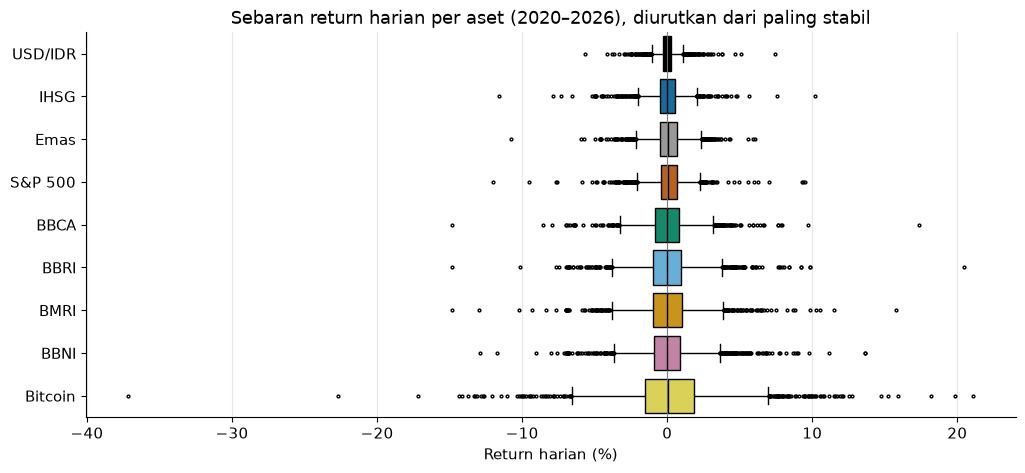

5 hari dengan return IHSG paling ekstrem:
[datetime.date(2026, 10, 16) datetime.date(2020, 3, 26)
 datetime.date(2025, 4, 8) datetime.date(2026, 6, 9)
 datetime.date(2026, 1, 28)]


In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
urutan = ret.std().sort_values().index
sns.boxplot(data=ret[urutan], orient="h", palette=[WARNA[a] for a in urutan],
            fliersize=2, linewidth=1, ax=ax)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Return harian (%)"); ax.set_ylabel("")
ax.set_title("Sebaran return harian per aset (2020–2026), diurutkan dari paling stabil")
simpan("00_boxplot_return")
plt.show()

# 5 hari paling ekstrem untuk IHSG
print("5 hari dengan return IHSG paling ekstrem:")
print(ret["IHSG"].abs().sort_values(ascending=False).head().index.date)

## 3. Visualisasi

> **Untuk semua anggota:** pakai variabel `close`, `volume`, `ret`, `norm`, `close_m` dari Bagian 2. Warna tiap aset pakai dict `WARNA[...]` supaya konsisten di semua grafik. Simpan grafik pakai `simpan("nama_file")` sebelum `plt.show()`. **Jangan ubah sel milik anggota lain.**

### 3.1 Line Plot
*(Raffa)*

Saran: pergerakan harga penutupan **IHSG** 2020–2026, beri anotasi pada peristiwa penting (mis. crash COVID Maret 2020).

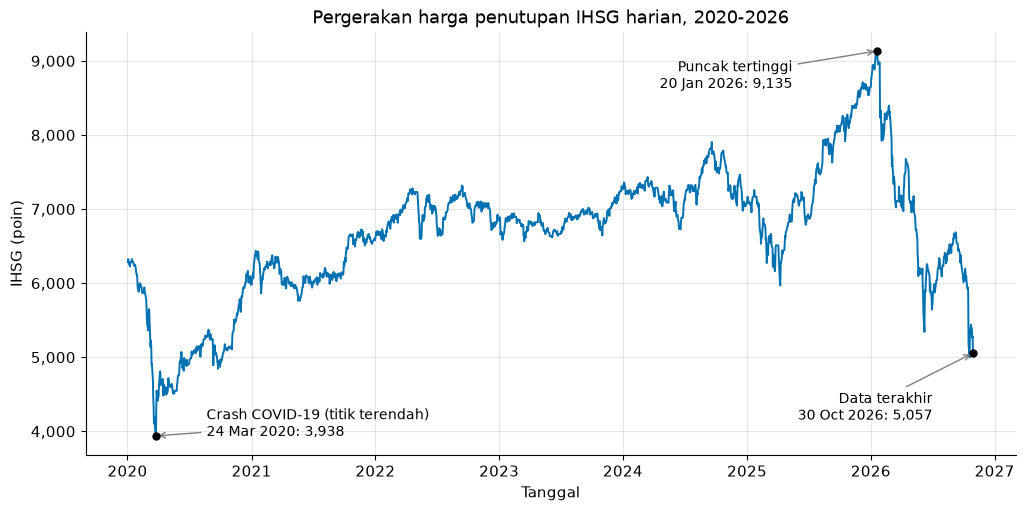

In [12]:
# Line Plot: harga penutupan IHSG 2020-2026 dengan anotasi titik penting
ihsg = close["IHSG"]
t_low, t_high, t_last = ihsg.idxmin(), ihsg.idxmax(), ihsg.index[-1]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(ihsg.index, ihsg, color=WARNA["IHSG"], lw=1.4)

def anotasi(tgl, teks, dx, dy, ha="left"):
    ax.annotate(f"{teks}\n{tgl:%d %b %Y}: {ihsg[tgl]:,.0f}", xy=(tgl, ihsg[tgl]),
                xytext=(tgl + pd.Timedelta(days=dx), ihsg[tgl] + dy), ha=ha,
                arrowprops=dict(arrowstyle="->", color="grey"), fontsize=10)
    ax.scatter([tgl], [ihsg[tgl]], color="black", zorder=5, s=25)

anotasi(t_low, "Crash COVID-19 (titik terendah)", 150, 0)
anotasi(t_high, "Puncak tertinggi", -250, -500, ha="right")
anotasi(t_last, "Data terakhir", -120, -900, ha="right")

ax.set_title("Pergerakan harga penutupan IHSG harian, 2020-2026")
ax.set_xlabel("Tanggal"); ax.set_ylabel("IHSG (poin)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
simpan("01_line_ihsg")
plt.show()

**Interpretasi:**

- **Crash COVID:** dari ~6.300 (awal 2020) ke 3.938 (24 Mar 2020), turun ~37% dalam 3 bulan.
- **Pulih pelan**, balik ke level sebelum COVID di awal 2021.
- **2022-2024** jalan di tempat, di kisaran 6.500-7.500.
- **Reli 2025:** naik terus dari April 2025 sampai puncak 9.135 (20 Jan 2026).
- **Koreksi 2026:** jatuh ke 5.057 (30 Okt 2026), turun ~45% dari puncak, lebih dalam dari COVID. Turunnya bertahap, sempat naik sebentar tapi tidak bertahan.
- **Intinya:** naik dalam jangka panjang, tapi kena 2 guncangan besar (2020 dan 2026).
- **Batasan:** grafik hanya menunjukkan pergerakan, bukan penyebab atau prediksi.

### 3.2 Area Plot
*(Raffa)*

Saran: **stacked area volume** transaksi 4 saham bank (BBCA, BBRI, BMRI, BBNI), mis. dirata-rata per bulan pakai `volume[[...]].resample("ME").sum()` agar tidak terlalu ramai.

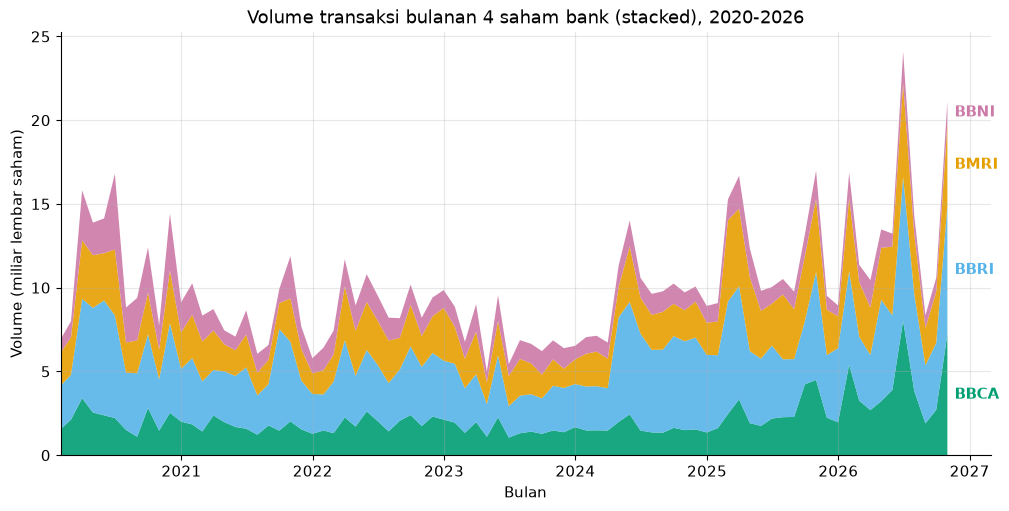

In [13]:
# Area Plot: stacked area volume bulanan 4 saham bank
bank = ["BBCA", "BBRI", "BMRI", "BBNI"]
vol_m = volume[bank].resample("ME").sum() / 1e9      # miliar lembar per bulan

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.stackplot(vol_m.index, vol_m.T, labels=bank,
             colors=[WARNA[b] for b in bank], alpha=0.9)
# direct labeling di ujung kanan (tanpa legend), posisi di tengah tiap lapisan
kum = vol_m.cumsum(axis=1).iloc[-1]
for b in bank:
    ax.text(vol_m.index[-1] + pd.Timedelta(days=20), kum[b] - vol_m[b].iloc[-1] / 2, b,
            color=WARNA[b], va="center", fontweight="bold")
ax.set_xlim(vol_m.index[0], vol_m.index[-1] + pd.Timedelta(days=120))
ax.set_title("Volume transaksi bulanan 4 saham bank (stacked), 2020-2026")
ax.set_xlabel("Bulan"); ax.set_ylabel("Volume (miliar lembar saham)")
simpan("02_area_volume_bank")
plt.show()

In [14]:
# Cek: volume (lembar) vs perkiraan nilai transaksi (harga x volume) per saham bank
# Catatan: harga close sudah adjusted, jadi nilai ini perkiraan kasar, bukan nilai transaksi resmi BEI.
nilai = (close[bank] * volume[bank]).sum() / 1e12      # triliun rupiah, total 2020-2026
porsi = pd.DataFrame({
    "rata-rata harga (Rp)": close[bank].mean(),
    "volume/bulan (miliar lembar)": vol_m.mean(),
    "porsi volume (%)": volume[bank].sum() / volume[bank].sum().sum() * 100,
    "porsi nilai (%)": nilai / nilai.sum() * 100,
})
porsi.round(1)

,rata-rata harga (Rp),volume/bulan (miliar lembar),porsi volume (%),porsi nilai (%)
Nama,,,,
BBCA,"7,008.30",2.20,21.60,36.10
BBRI,"3,306.50",4.00,40.00,31.70
BMRI,"3,572.70",2.50,24.90,21.90
BBNI,"3,299.20",1.40,13.60,10.30


**Interpretasi:**

- **Volume terbanyak:** BBRI (~4 miliar lembar/bulan), lalu BMRI, BBCA, BBNI.
- **Ini jumlah lembar, bukan rupiah.** Kalau dihitung dalam rupiah (tabel di atas), BBCA paling besar karena harganya ~2x lipat. BBRI tebal karena harganya murah, jadi banyak lembar pindah tangan.
- **Pertengahan 2020:** volume tinggi, pasar kacau karena pandemi.
- **2021-2023:** lebih sepi, terendah di April 2023.
- **Sejak 2024:** naik lagi, tertinggi Juni 2026 (~24 miliar lembar) saat IHSG turun. Mungkin karena banyak yang jual, tapi volume tidak bisa membedakan beli dan jual, jadi masih dugaan.
- **Kekurangan stacked area:** susah membandingkan satu saham antarwaktu, terutama BBNI yang ada di paling atas.

### 3.3 Multiple Time Series
*(Tristan)*

Saran: bandingkan `norm` (basis 100) beberapa aset lintas kategori, mis. IHSG, S&P 500, Bitcoin, Emas, USD/IDR. **Wajib direct labeling di ujung garis, tanpa legend.** Bitcoin naik jauh lebih tinggi, jadi pertimbangkan skala log (`ax.set_yscale("log")`).

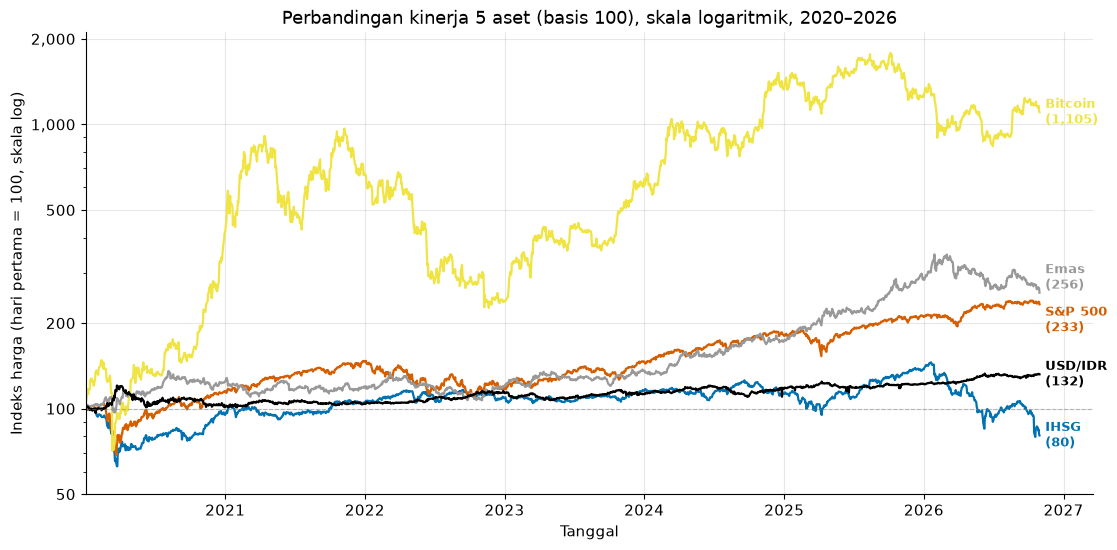

In [15]:
# Multiple Time Series: 5 aset lintas kategori, direct labeling, skala log
pilihan = ["IHSG", "S&P 500", "Bitcoin", "Emas", "USD/IDR"]

fig, ax = plt.subplots(figsize=(13, 6))

# Offset manual (faktor pengali di skala log) agar label tidak bertumpuk
label_offset = {"IHSG": 1.0, "S&P 500": 0.88, "Bitcoin": 1.0,
                "Emas": 1.13, "USD/IDR": 1.0}

for aset in pilihan:
    ax.plot(norm.index, norm[aset], color=WARNA[aset], lw=1.6)

    # Direct labeling di ujung kanan garis (tanpa legend)
    y_end = norm[aset].iloc[-1]
    y_label = y_end * label_offset[aset]
    ax.text(norm.index[-1] + pd.Timedelta(days=15), y_label,
            f"{aset}\n({y_end:,.0f})",
            color=WARNA[aset], va="center", fontsize=9, fontweight="bold")

ax.set_yscale("log")
ax.set_title("Perbandingan kinerja 5 aset (basis 100), skala logaritmik, 2020\u20132026")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Indeks harga (hari pertama = 100, skala log)")

# Tick khusus di skala log agar mudah dibaca
ax.set_yticks([50, 100, 200, 500, 1000, 2000])
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(norm.index[0], norm.index[-1] + pd.Timedelta(days=140))
ax.axhline(100, color="grey", ls="--", lw=0.8, alpha=0.5)   # garis basis 100

simpan("03_multi_timeseries")
plt.show()

**Interpretasi:**

- Grafik membandingkan 5 aset dari 5 kategori berbeda menggunakan **indeks basis 100** (hari pertama = 100) supaya bisa dibandingkan meskipun satuannya beda-beda. Skala logaritmik dipakai karena Bitcoin naik jauh lebih tinggi dari aset lain.

- **Bitcoin paling unggul:** dari 100 menjadi ±1.105 (naik ±11× lipat). Tapi pergerakannya paling liar — sempat turun tajam di 2022 (crash kripto) sebelum naik lagi.

- **Emas dan S&P 500 bersaing ketat:** emas di 256, S&P 500 di 233 (masing-masing naik ±150% dan ±133%). Keduanya naik relatif stabil, tapi S&P 500 lebih fluktuatif.

- **USD/IDR naik ke 132**, artinya rupiah melemah ±32% terhadap dolar. Pergerakannya paling tenang dari semua aset.

- **IHSG satu-satunya aset yang turun** (indeks 80, atau −20%). Setelah sempat pulih dan menyentuh puncak di awal 2026, IHSG jatuh tajam di 2026.

- **Kesimpulan visual:** investor Indonesia yang hanya pegang IHSG mendapat return negatif, sedangkan aset global (S&P 500, emas, Bitcoin) naik signifikan. Pelemahan rupiah memperburuk daya beli relatif.

- **Catatan:** skala log membuat perubahan persentase yang sama terlihat setinggi yang sama di mana pun di grafik, sehingga perbandingan lebih adil.

### 3.4 Seasonal Plot / Calendar Heatmap
*(Tristan)*

Saran: heatmap **rata-rata return bulanan IHSG** (sumbu Y = tahun, sumbu X = bulan) atau seasonal plot `close_m` per tahun. Return bisa positif/negatif → pakai skala warna **diverging** dengan titik tengah 0 (mis. `cmap="RdBu"`, `center=0`).

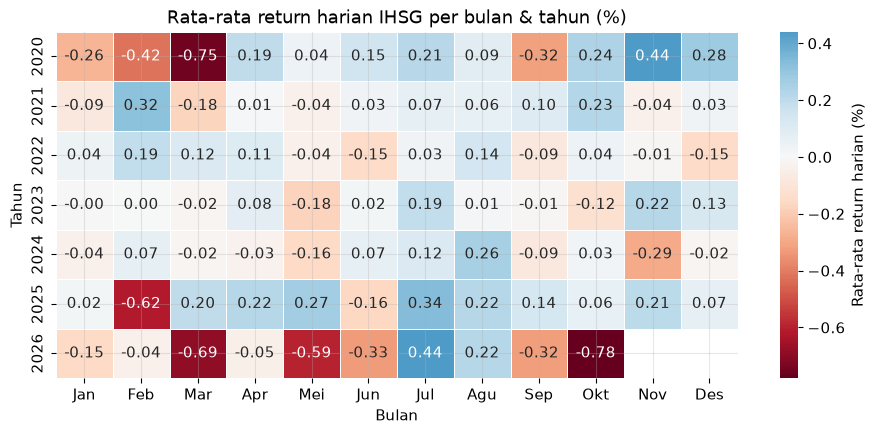

In [16]:
# Calendar Heatmap: rata-rata return harian IHSG per bulan & tahun
ret_ihsg = ret["IHSG"]
pivot = ret_ihsg.groupby([ret_ihsg.index.year, ret_ihsg.index.month]).mean().unstack()
pivot.index.name = "Tahun"
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
         "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
pivot.columns = BULAN[:pivot.shape[1]]

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(pivot, cmap="RdBu", center=0, annot=True, fmt=".2f",
            linewidths=0.6, linecolor="white",
            cbar_kws={"label": "Rata-rata return harian (%)"},
            ax=ax)
ax.set_title("Rata-rata return harian IHSG per bulan & tahun (%)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Tahun")

simpan("04_heatmap_return_ihsg")
plt.show()

**Interpretasi:**

- Heatmap menampilkan **rata-rata return harian IHSG (%)** untuk setiap kombinasi bulan dan tahun. Warna biru = positif (naik), merah = negatif (turun), makin gelap makin ekstrem.

- **Maret cenderung buruk:** merah di 5 dari 7 tahun. Maret 2020 (−0,75%) dan Maret 2026 (−0,69%) paling parah karena crash COVID dan koreksi 2026.

- **Juli dan Agustus cenderung positif:** biru di hampir semua tahun. Juli 2026 (+0,44%) adalah bulan terbaik 2026.

- **2026 didominasi merah**, terutama Mei (−0,59%), Juni (−0,33%), dan Oktober (−0,78%). Ini konsisten dengan tren turun IHSG yang terlihat di Line Plot.

- **2025 didominasi biru** (9 dari 12 bulan positif), kecuali Februari (−0,62%) dan Juni (−0,16%). Ini adalah periode reli IHSG.

- **Pola musiman tidak terlalu kuat:** tidak ada bulan yang selalu positif atau selalu negatif di semua tahun. Ini wajar karena pasar saham dipengaruhi banyak faktor fundamental dan sentimen, bukan hanya musim.

- **Catatan:** angka di heatmap adalah rata-rata return harian (bukan bulanan). Misalnya −0,75% per hari di Maret 2020 berarti rata-rata IHSG turun 0,75% setiap hari kerja di bulan itu.

## 4. Analisis Tren
*(Naufal Rafif)*

### 4.1 Moving Average
Saran: MA **20 hari** (± 1 bulan bursa) dan **200 hari** (± 1 tahun bursa) di atas harga asli IHSG. Jelaskan trade-off: window besar → kurva lebih halus, tapi NaN di awal lebih banyak dan lebih telat merespons perubahan.

In [17]:
# TODO Naufal Rafif: Moving Average (min. 2 window)


### 4.2 Fitting Model
Saran: `numpy.polyfit` linear & polynomial pada IHSG, atau fit eksponensial (`polyfit` pada `log(harga)`) untuk Bitcoin/Emas. Sumbu x pakai angka hari ke-n, bukan tanggal.

In [18]:
# TODO Naufal Rafif: Fitting model (numpy.polyfit)


**Interpretasi:** *(Naufal Rafif — tulis di sini)*

## 5. Kesimpulan
*(Naufal Ramadhan — min. 5 insight dari seluruh analisis)*

1.
2.
3.
4.
5.

## 6. Deklarasi Penggunaan AI
*(Naufal Ramadhan — rekap dari file log di folder `Log/`)*

Kami menyatakan bahwa dalam pengerjaan tugas ini kami menggunakan bantuan AI generatif sebagaimana dirinci pada tabel berikut. Seluruh hasil telah kami periksa, pahami, dan sesuaikan, dan kami bertanggung jawab penuh atas isi tugas ini.

| No | Tools | Bagian | Bentuk Bantuan / Prompt | Tingkat Ketergantungan |
|----|-------|--------|-------------------------|------------------------|
| 1 | Claude (Claude Code) | Perencanaan proyek (Davu) | Membaca soal, membagi jobdesk, membuat struktur folder & README | Sedang |
| 2 | Claude (Claude Code) | Dataset & kerangka notebook (Davu) | Script unduh Yahoo Finance, cleaning, data profiling, kerangka notebook | Tinggi |
| 3 | Claude (Claude Code) | Line Plot & Area Plot (Raffa) | Menulis kode Line Plot IHSG dan Area Plot volume bank, draf interpretasi, penjelasan kode | Tinggi |
| 4 | Antigravity (Google Deepmind) | Multiple Time Series & Calendar Heatmap (Tristan) | Menulis kode Multiple Time Series (direct labeling, skala log) dan Calendar Heatmap (return IHSG) | Tinggi |
| 5 | | | | |


## 7. Daftar Pustaka

1. Yahoo Finance. (2026). *Historical prices: ^JKSE, ^GSPC, BBCA.JK, BBRI.JK, BMRI.JK, BBNI.JK, BTC-USD, GC=F, IDR=X*. Diakses 2 November 2026, dari https://finance.yahoo.com
2. Aroussi, R. (2026). *yfinance: Download market data from Yahoo! Finance's API* [Python library]. https://github.com/ranaroussi/yfinance
3. Wilke, C. O. (2019). *Fundamentals of Data Visualization*. O'Reilly Media. https://clauswilke.com/dataviz/
4.